In [35]:
import pandas as pd
import numpy as np
from pathlib import Path

project_folder = Path.cwd().parent
orders = pd.read_csv(project_folder / "orders DA.csv")

print("Dataset shape:", orders.shape)
print(orders.head())

Dataset shape: (50000, 19)
    order_id customer_id  order_date order_time      status       city  \
0  ORD000001   CUST02946  22-05-2025   17:10:00  Processing       Pune   
1  ORD000002   CUST04232  16-10-2023   05:32:00   Delivered   Ludhiana   
2  ORD000003   CUST08078  08-10-2023   12:32:00   Cancelled     Meerut   
3  ORD000004   CUST09612  02-10-2023   08:05:00   Delivered     Nashik   
4  ORD000005   CUST03065  15-06-2024   20:19:00   Delivered  Moradabad   

           state  pincode  total_amount  gst_amount  shipping_charge  \
0    Maharashtra   300862     100984.19    16364.64                0   
1         Punjab   387852     254478.01    41599.80                0   
2  Uttar Pradesh   294014      32557.06     3562.92                0   
3    Maharashtra   626047      24836.94     3092.88                0   
4  Uttar Pradesh   409210     156689.29    25092.36                0   

   discount_amount  final_amount    payment_method  shipping_partner  \
0         20486.45     

In [36]:
from pathlib import Path

folder = Path.cwd().parent
orders = pd.read_csv(folder / "orders DA.csv")

print(orders.shape)

(50000, 19)


In [37]:
import pandas as pd

orders["order_date"] = pd.to_datetime(
    orders["order_date"], dayfirst=True, errors="coerce"
)

print("Missing dates:", orders["order_date"].isna().sum())
print("Date range:", orders["order_date"].min(), "to", orders["order_date"].max())

Missing dates: 0
Date range: 2023-06-24 00:00:00 to 2025-06-23 00:00:00


In [38]:
monthly_orders = orders.groupby(
    orders["order_date"].dt.to_period("M")
).size()

print(monthly_orders)

order_date
2023-06     444
2023-07    2081
2023-08    2091
2023-09    2104
2023-10    2060
2023-11    2114
2023-12    2090
2024-01    2090
2024-02    1907
2024-03    2111
2024-04    2131
2024-05    2167
2024-06    2072
2024-07    2025
2024-08    2146
2024-09    2011
2024-10    2131
2024-11    2084
2024-12    2148
2025-01    2239
2025-02    1879
2025-03    2167
2025-04    2024
2025-05    2134
2025-06    1550
Freq: M, dtype: int64


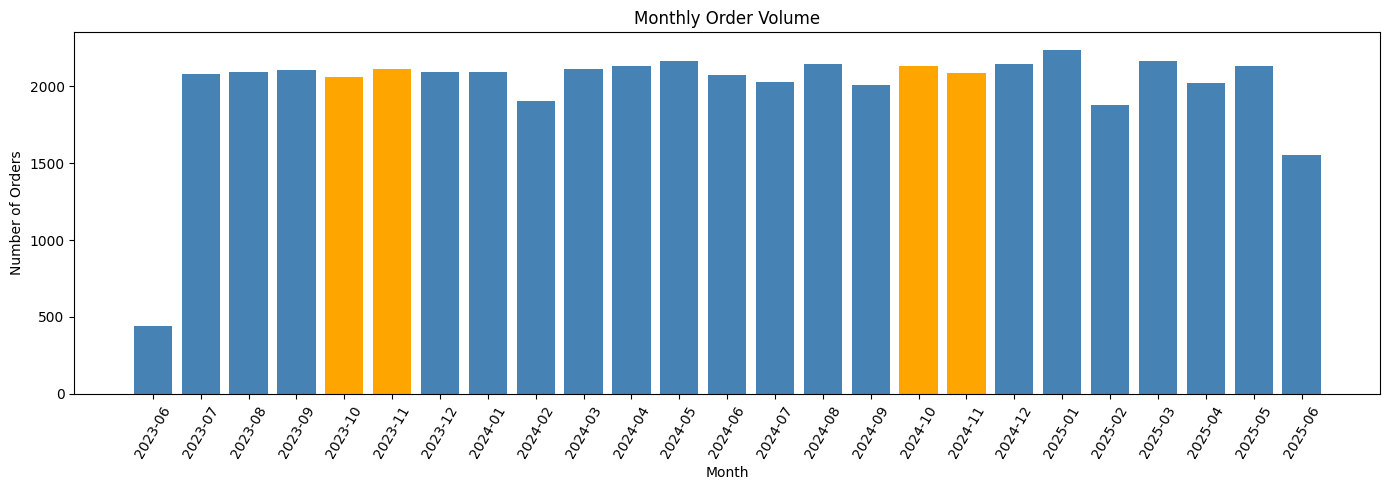

In [39]:
import matplotlib.pyplot as plt

months = monthly_orders.index.astype(str)
colors = [
    "orange" if m.endswith("-10") or m.endswith("-11") else "steelblue"
    for m in months
]

plt.figure(figsize=(14, 5))
plt.bar(months, monthly_orders.values, color=colors)
plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\01_monthly_order_volume.png", dpi=300, bbox_inches="tight")
plt.show()

### Findings — Monthly Order Volume

1. Monthly orders were generally around 2,000–2,200 during most full months.
2. January 2025 had the highest order volume, with 2,239 orders.
3. June 2023 and June 2025 are partial months, so their lower counts should not be compared directly with full months.

In [40]:
print(orders[["order_date", "final_amount"]].head())
print(orders["final_amount"].dtype)

  order_date  final_amount
0 2025-05-22     100984.19
1 2023-10-16     254478.01
2 2023-10-08      32557.06
3 2023-10-02      24836.94
4 2024-06-15     156689.29
float64


In [41]:
monthly_gmv = orders.groupby(
    orders["order_date"].dt.to_period("M")
)["final_amount"].sum()

print(monthly_gmv)

order_date
2023-06    2.738485e+07
2023-07    1.289205e+08
2023-08    1.281220e+08
2023-09    1.374625e+08
2023-10    1.324709e+08
2023-11    1.372634e+08
2023-12    1.369234e+08
2024-01    1.314500e+08
2024-02    1.209459e+08
2024-03    1.336701e+08
2024-04    1.315097e+08
2024-05    1.363584e+08
2024-06    1.237410e+08
2024-07    1.270283e+08
2024-08    1.319235e+08
2024-09    1.305253e+08
2024-10    1.335183e+08
2024-11    1.262641e+08
2024-12    1.330895e+08
2025-01    1.379291e+08
2025-02    1.141167e+08
2025-03    1.364932e+08
2025-04    1.308222e+08
2025-05    1.358494e+08
2025-06    1.036033e+08
Freq: M, Name: final_amount, dtype: float64


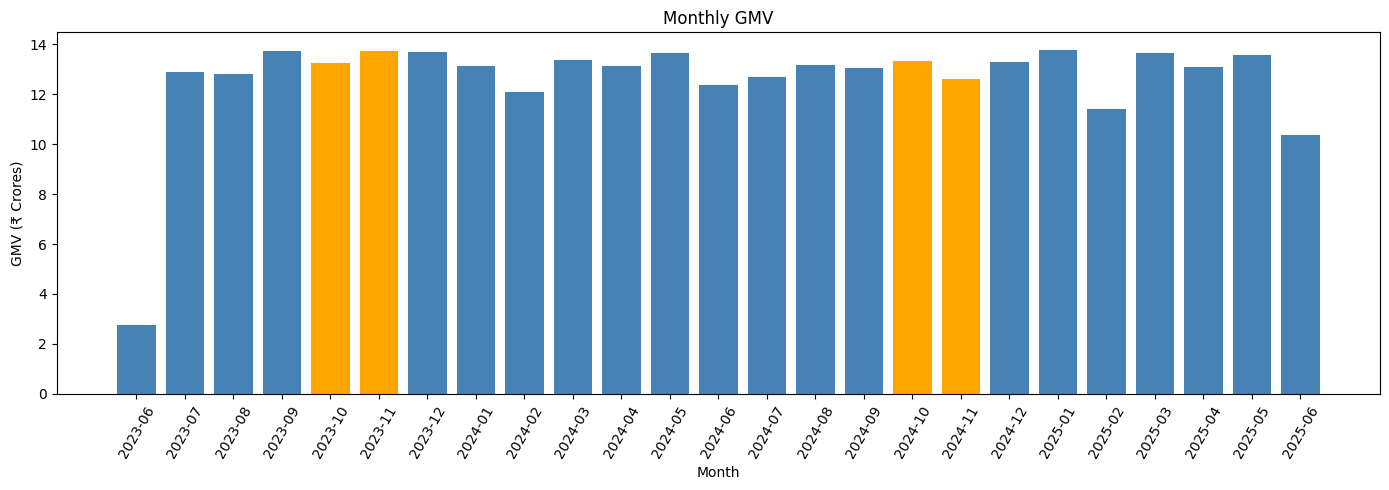

In [42]:
import matplotlib.pyplot as plt

months = monthly_gmv.index.astype(str)
gmv_crores = monthly_gmv.values / 10000000

colors = [
    "orange" if m.endswith("-10") or m.endswith("-11")
    else "steelblue"
    for m in months
]

plt.figure(figsize=(14, 5))
plt.bar(months, gmv_crores, color=colors)
plt.title("Monthly GMV")
plt.xlabel("Month")
plt.ylabel("GMV (₹ Crores)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\02_monthly_GMV.png", dpi=300, bbox_inches="tight")
plt.show()

### Findings — Monthly GMV

1. Monthly GMV was generally around ₹12–14 crore during most full months.
2. January 2025 recorded the highest monthly GMV, at approximately ₹13.79 crore.
3. June 2023 and June 2025 represent partial months, so their lower GMV should not be compared directly with full months.

In [43]:
from pathlib import Path

project_folder = Path.cwd().parent

print(project_folder)

order_items = pd.read_csv(
    project_folder / "order_items DA.csv"
)

products = pd.read_csv(
    project_folder / "products DA.csv"
)

print("Order items columns:")
print(order_items.columns.tolist())

print("\nProducts columns:")
print(products.columns.tolist())

d:\internship\IndiaKart_Ecommerce_Analytics
Order items columns:
['item_id', 'order_id', 'product_id', 'product_name', 'category', 'quantity', 'unit_price', 'gst_rate', 'gst_amount', 'discount_amount', 'total_price']

Products columns:
['product_id', 'product_name', 'category', 'subcategory', 'brand', 'sku', 'mrp', 'selling_price', 'cost_price', 'gst_rate', 'hsn_code', 'weight_grams', 'supplier_id', 'rating', 'review_count', 'is_active', 'launch_date']


In [44]:
category_revenue = order_items.groupby(
    "category"
)["total_price"].sum().sort_values(ascending=False)

print(category_revenue)

category
Electronics         1.642423e+09
Sports & Fitness    4.972384e+08
Home & Kitchen      2.442952e+08
Fashion             1.481553e+08
Automotive          1.234851e+08
Office Supplies     9.302935e+07
Toys & Baby         4.658385e+07
Beauty & Health     3.301811e+07
Grocery             1.871868e+07
Books               1.394589e+07
Name: total_price, dtype: float64


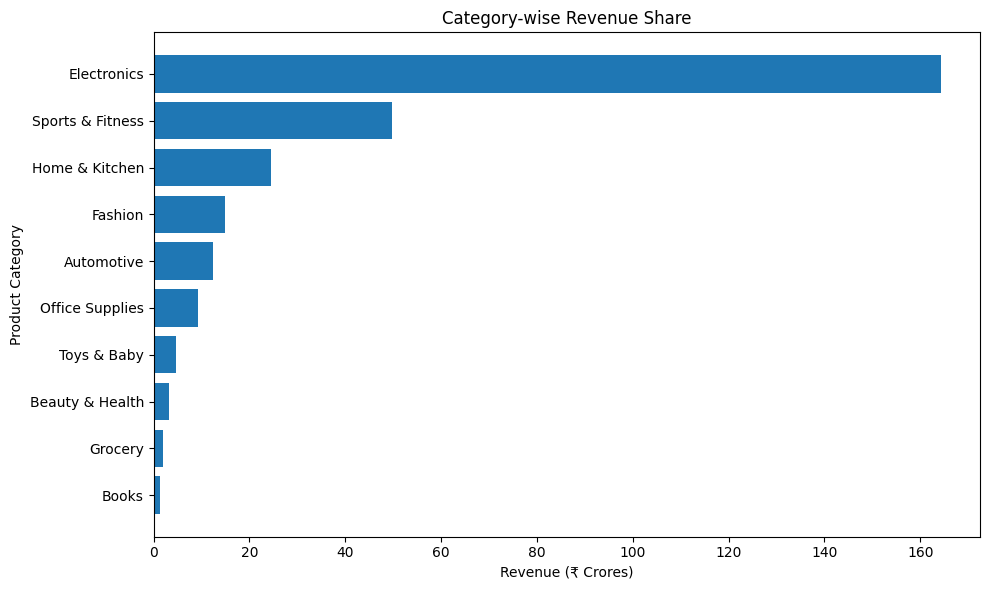

In [45]:
import matplotlib.pyplot as plt

revenue_crores = category_revenue / 10000000

plt.figure(figsize=(10, 6))
plt.barh(revenue_crores.index, revenue_crores.values)
plt.title("Category-wise Revenue Share")
plt.xlabel("Revenue (₹ Crores)")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\03_category_revenue_share.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Findings — Category-wise Revenue Share

1. Electronics generated the highest revenue at approximately ₹164.24 crore.
2. Sports & Fitness ranked second at approximately ₹49.72 crore, followed by Home & Kitchen at ₹24.43 crore.
3. Revenue is heavily concentrated in Electronics, indicating that this category contributes substantially more than the other product categories.

In [46]:
print(orders["status"].value_counts())

status
Delivered     32499
Cancelled      5996
Shipped        5071
Returned       3933
Processing     2501
Name: count, dtype: int64


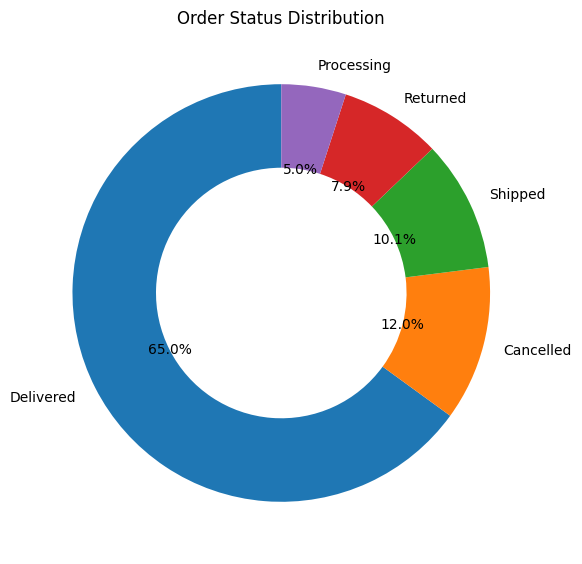

In [47]:
import matplotlib.pyplot as plt

status_counts = orders["status"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Order Status Distribution")
plt.tight_layout()

plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\04_order_status_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings — Order Status Distribution

1. Delivered orders account for 65.0% of all orders (32,499 out of 50,000).
2. Cancelled orders account for approximately 12.0%, while Returned orders account for approximately 7.9%.
3. The remaining orders are Shipped (approximately 10.1%) and Processing (approximately 5.0%).

In [48]:
customers = pd.read_csv(
    project_folder / "customers DA.csv"
)

print("Orders columns:")
print(orders.columns.tolist())

print("\nCustomer columns:")
print(customers.columns.tolist())

Orders columns:
['order_id', 'customer_id', 'order_date', 'order_time', 'status', 'city', 'state', 'pincode', 'total_amount', 'gst_amount', 'shipping_charge', 'discount_amount', 'final_amount', 'payment_method', 'shipping_partner', 'tracking_id', 'delivered_date', 'is_cod', 'channel']

Customer columns:
['customer_id', 'first_name', 'last_name', 'email', 'phone', 'city', 'state', 'pincode', 'gender', 'age', 'segment', 'registration_date', 'last_login_date', 'is_verified', 'is_active', 'total_orders', 'total_spent']


In [49]:
top_states = orders["state"].value_counts().head(10)

print(top_states)

state
Uttar Pradesh     9507
Maharashtra       8179
Gujarat           3811
Madhya Pradesh    3741
Tamil Nadu        3664
Karnataka         3102
Rajasthan         3047
West Bengal       2103
Punjab            2073
Jharkhand         2044
Name: count, dtype: int64


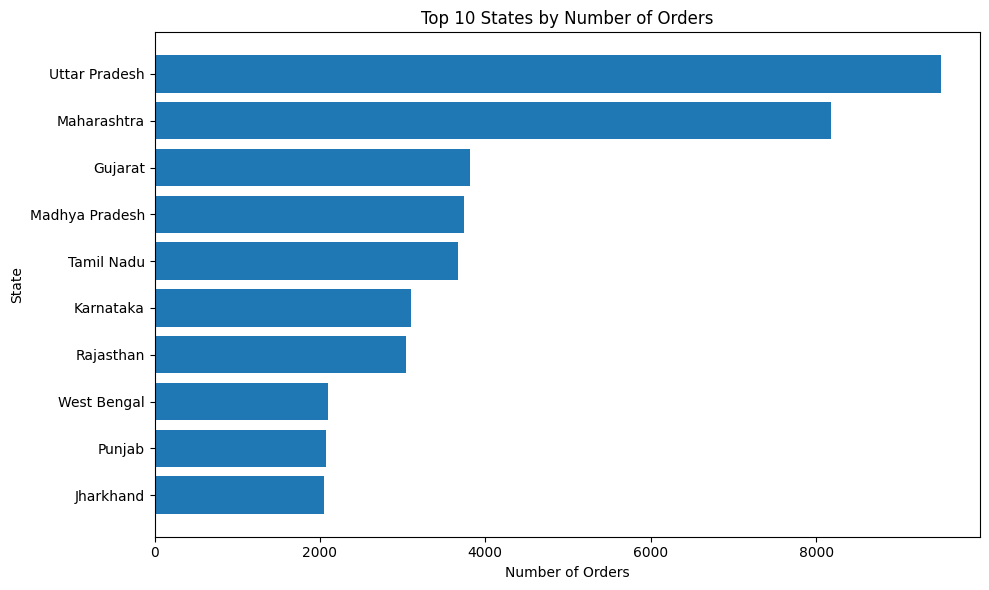

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(top_states.index[::-1], top_states.values[::-1])

plt.title("Top 10 States by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("State")
plt.tight_layout()

plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\05_top_10_states.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings — Top 10 States by Orders

1. Uttar Pradesh recorded the highest number of orders, with 9,507.
2. Maharashtra ranked second with 8,179 orders, followed by Gujarat with 3,811.
3. Order volume is concentrated in Uttar Pradesh and Maharashtra compared with the other states in the top 10.

In [51]:
print(customers["segment"].value_counts())

segment
Regular     4026
Budget      2505
Premium     1501
New         1488
Inactive     480
Name: count, dtype: int64


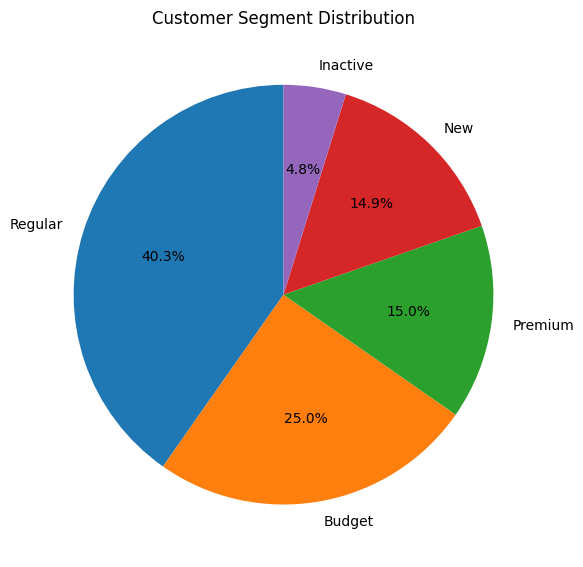

In [52]:
import matplotlib.pyplot as plt

segment_counts = customers["segment"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Segment Distribution")
plt.tight_layout()

plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\06_customer_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings — Customer Segment Distribution

1. Regular customers form the largest segment, with 4,026 customers (40.26%).
2. Budget customers account for 25.05%, while Premium customers account for 15.01%.
3. New customers represent 14.88% and Inactive customers represent 4.80% of the customer base.

In [53]:
print(orders["payment_method"].value_counts())

payment_method
UPI                 17570
Credit Card         10007
Debit Card           7624
Cash on Delivery     5883
Net Banking          4026
EMI                  2943
Wallet               1947
Name: count, dtype: int64


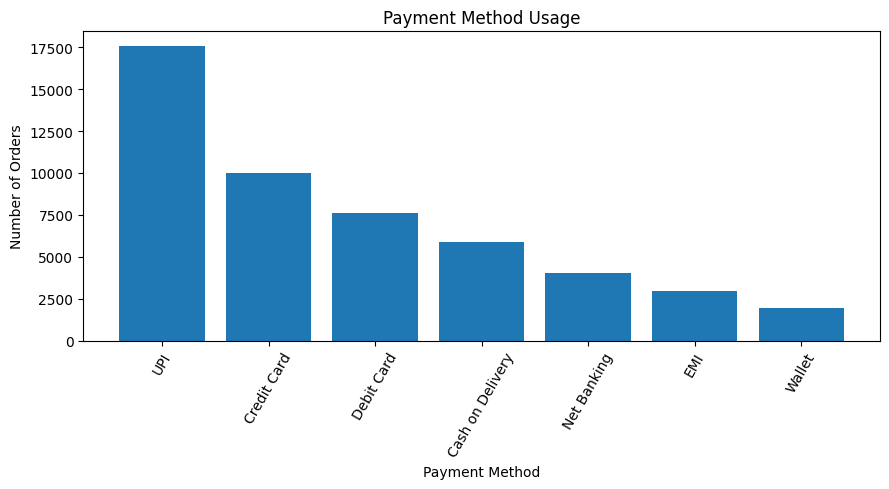

In [54]:
import matplotlib.pyplot as plt

payment_counts = orders["payment_method"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(payment_counts.index, payment_counts.values)

plt.title("Payment Method Usage")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\07_payment_method_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings — Payment Method Usage

1. UPI was the most popular payment method, used for 17,570 orders.
2. Credit Card ranked second with 10,007 orders, followed by Debit Card with 7,624 orders.
3. Wallet was the least-used method, with 1,947 orders.

In [55]:
import pandas as pd
from pathlib import Path

project_folder = Path.cwd().parent
customers = pd.read_csv(project_folder / "customers DA.csv")

print(customers["age"].describe())

count    10000.00000
mean        41.67630
std         13.83438
min         18.00000
25%         30.00000
50%         42.00000
75%         54.00000
max         65.00000
Name: age, dtype: float64


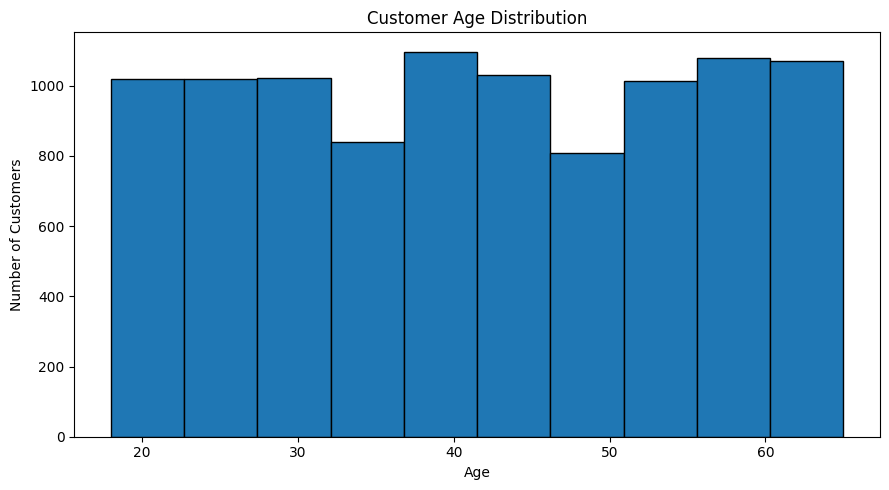

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(customers["age"], bins=10, edgecolor="black")

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\08_customer_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings — Customer Age Distribution

1. The dataset contains 10,000 customers aged between 18 and 65.
2. The average customer age is approximately 41.68 years, and the median age is 42.
3. Customer ages are distributed across the range, with no single age group overwhelmingly dominant.

In [57]:
returns = pd.read_csv(project_folder / "returns DA.csv")

print(returns["reason"].value_counts())

reason
Size Issue                 1196
Changed Mind               1150
Damaged in Transit         1143
Wrong Product Delivered    1135
Defective Product          1134
Not as Described           1125
Duplicate Order            1081
Quality Issue              1075
Delayed Delivery            484
Better Price Found          477
Name: count, dtype: int64


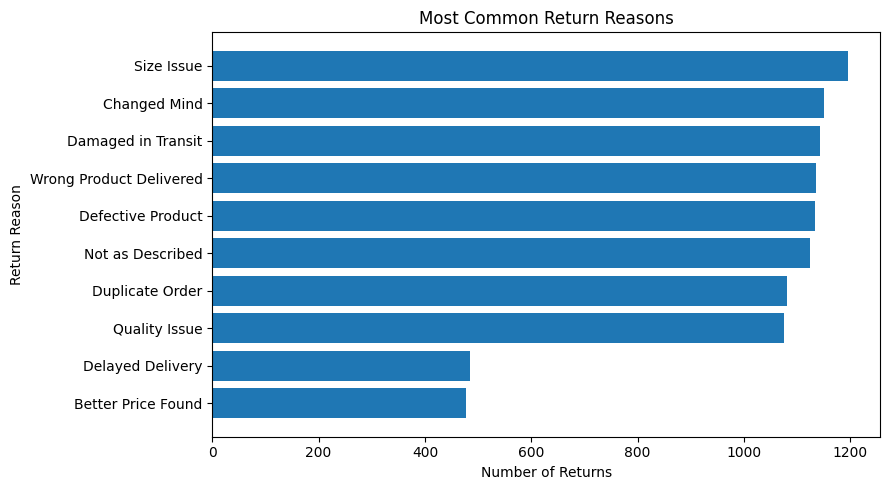

In [58]:
import matplotlib.pyplot as plt

return_counts = returns["reason"].value_counts()

plt.figure(figsize=(9, 5))
plt.barh(return_counts.index[::-1], return_counts.values[::-1])

plt.title("Most Common Return Reasons")
plt.xlabel("Number of Returns")
plt.ylabel("Return Reason")
plt.tight_layout()

plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\09_return_reasons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings — Return Reasons

1. Size Issue was the most common return reason, with 1,196 returns.
2. Changed Mind (1,150) and Damaged in Transit (1,143) were the next most common reasons.
3. Better Price Found (477) and Delayed Delivery (484) were the least common return reasons.

In [59]:
orders = pd.read_csv(project_folder / "orders DA.csv")
customers = pd.read_csv(project_folder / "customers DA.csv")

order_segments = orders.merge(
    customers[["customer_id", "segment"]],
    on="customer_id"
)

aov_by_segment = order_segments.groupby(
    "segment"
)["final_amount"].mean().sort_values(ascending=False)

print(aov_by_segment)

segment
Budget      64124.558428
New         63381.577666
Regular     63123.549510
Premium     61876.903871
Inactive    57120.144096
Name: final_amount, dtype: float64


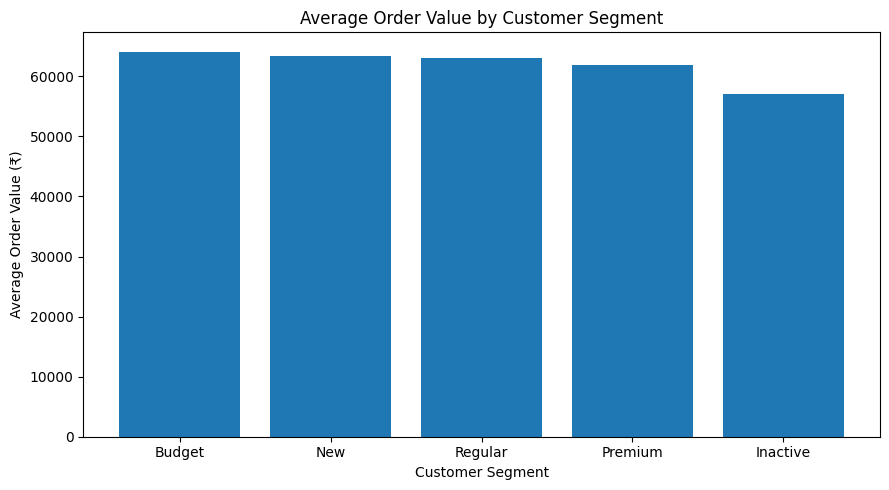

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(aov_by_segment.index, aov_by_segment.values)

plt.title("Average Order Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Value (₹)")
plt.tight_layout()

plt.savefig(
    r"D:\internship\IndiaKart_Ecommerce_Analytics\Phase 2 EDA visualizations\10_aov_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings — Average Order Value by Customer Segment

1. Budget customers had the highest average order value at approximately ₹64,125.
2. Premium customers averaged approximately ₹61,877 per order, lower than Budget, New, and Regular customers.
3. Inactive customers had the lowest average order value at approximately ₹57,120.